In [1]:
import os
from glob import glob  # find loss-history files
import re  # parse seed/fold from filenames

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from s2_metrics import r2_vs_ranking_plot, r2_comparison_plot
from s0_config import ISOFORMS, TARGET_COLS, UNDERPOWERED_N

# Results produced by main.ipynb
OUTPUT_DIR = 'outputs'
DMPNN_OUT = os.path.join(OUTPUT_DIR, 'dmpnn')
COMPARISON_OUT = os.path.join(OUTPUT_DIR, 'comparison')

In [2]:
# Shared plot style (same as main.ipynb)
plt.rcParams['figure.figsize'] = (13.33, 4)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 600
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 4
plt.rcParams['axes.grid'] = False
plt.rcParams['grid.alpha'] = 0.5
plt.rcParams['grid.linestyle'] = '-.'

    HDAC  Count  Percentage
0  HDAC1   5044    0.671012
1  HDAC2   1739    0.231342
2  HDAC3   1693    0.225223
3  HDAC4    874    0.116270
4  HDAC5    211    0.028070
5  HDAC6   3395    0.451643
6  HDAC7    205    0.027272
7  HDAC8   1890    0.251430
8  HDAC9    267    0.035519
Grouped data for the chart:
1     3794
2     1612
3     1175
4      458
≥5     478
Name: count, dtype: int64


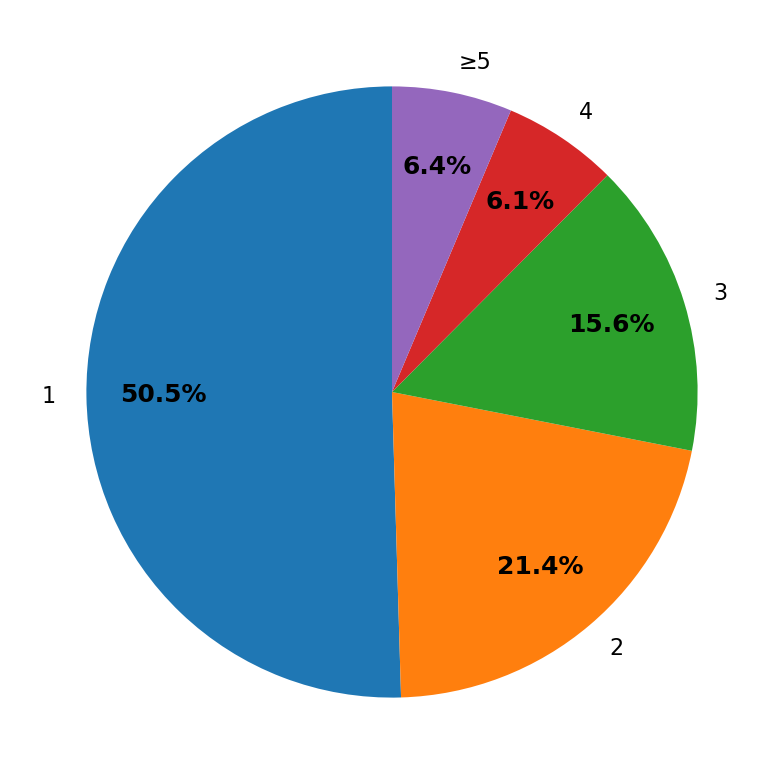

In [3]:
df = pd.read_excel('data.xlsx')

# Measured molecules per isoform, and the fraction of the dataset
db = pd.DataFrame([(col.replace('_HUMAN', ''), df[col].count(), df[col].count() / len(df)) for col in TARGET_COLS],
                  columns=['HDAC', 'Count', 'Percentage'])
print(db)

# How many isoforms each molecule was measured on
measurements_per_molecule = df[TARGET_COLS].notna().sum(axis=1)
valid_distribution = measurements_per_molecule.value_counts().sort_index()
# 1-4 measurements stay separate; 5+ are grouped into one slice
grouped_distribution = valid_distribution[valid_distribution.index < 5].copy()
grouped_distribution['≥5'] = valid_distribution[valid_distribution.index >= 5].sum()
print('Grouped data for the chart:')
print(grouped_distribution)

# Pie chart
plt.figure(figsize=(9, 8))
wedges, texts, autotexts = plt.pie(grouped_distribution,
                                   labels=grouped_distribution.index,
                                   autopct='%1.1f%%',
                                   startangle=90,
                                   pctdistance=0.75,
                                   textprops={'fontsize': 16})
for autotext in autotexts:  # bigger, bold percentage labels
    autotext.set_fontsize(18)
    autotext.set_fontweight('bold')
plt.tight_layout()
plt.show()

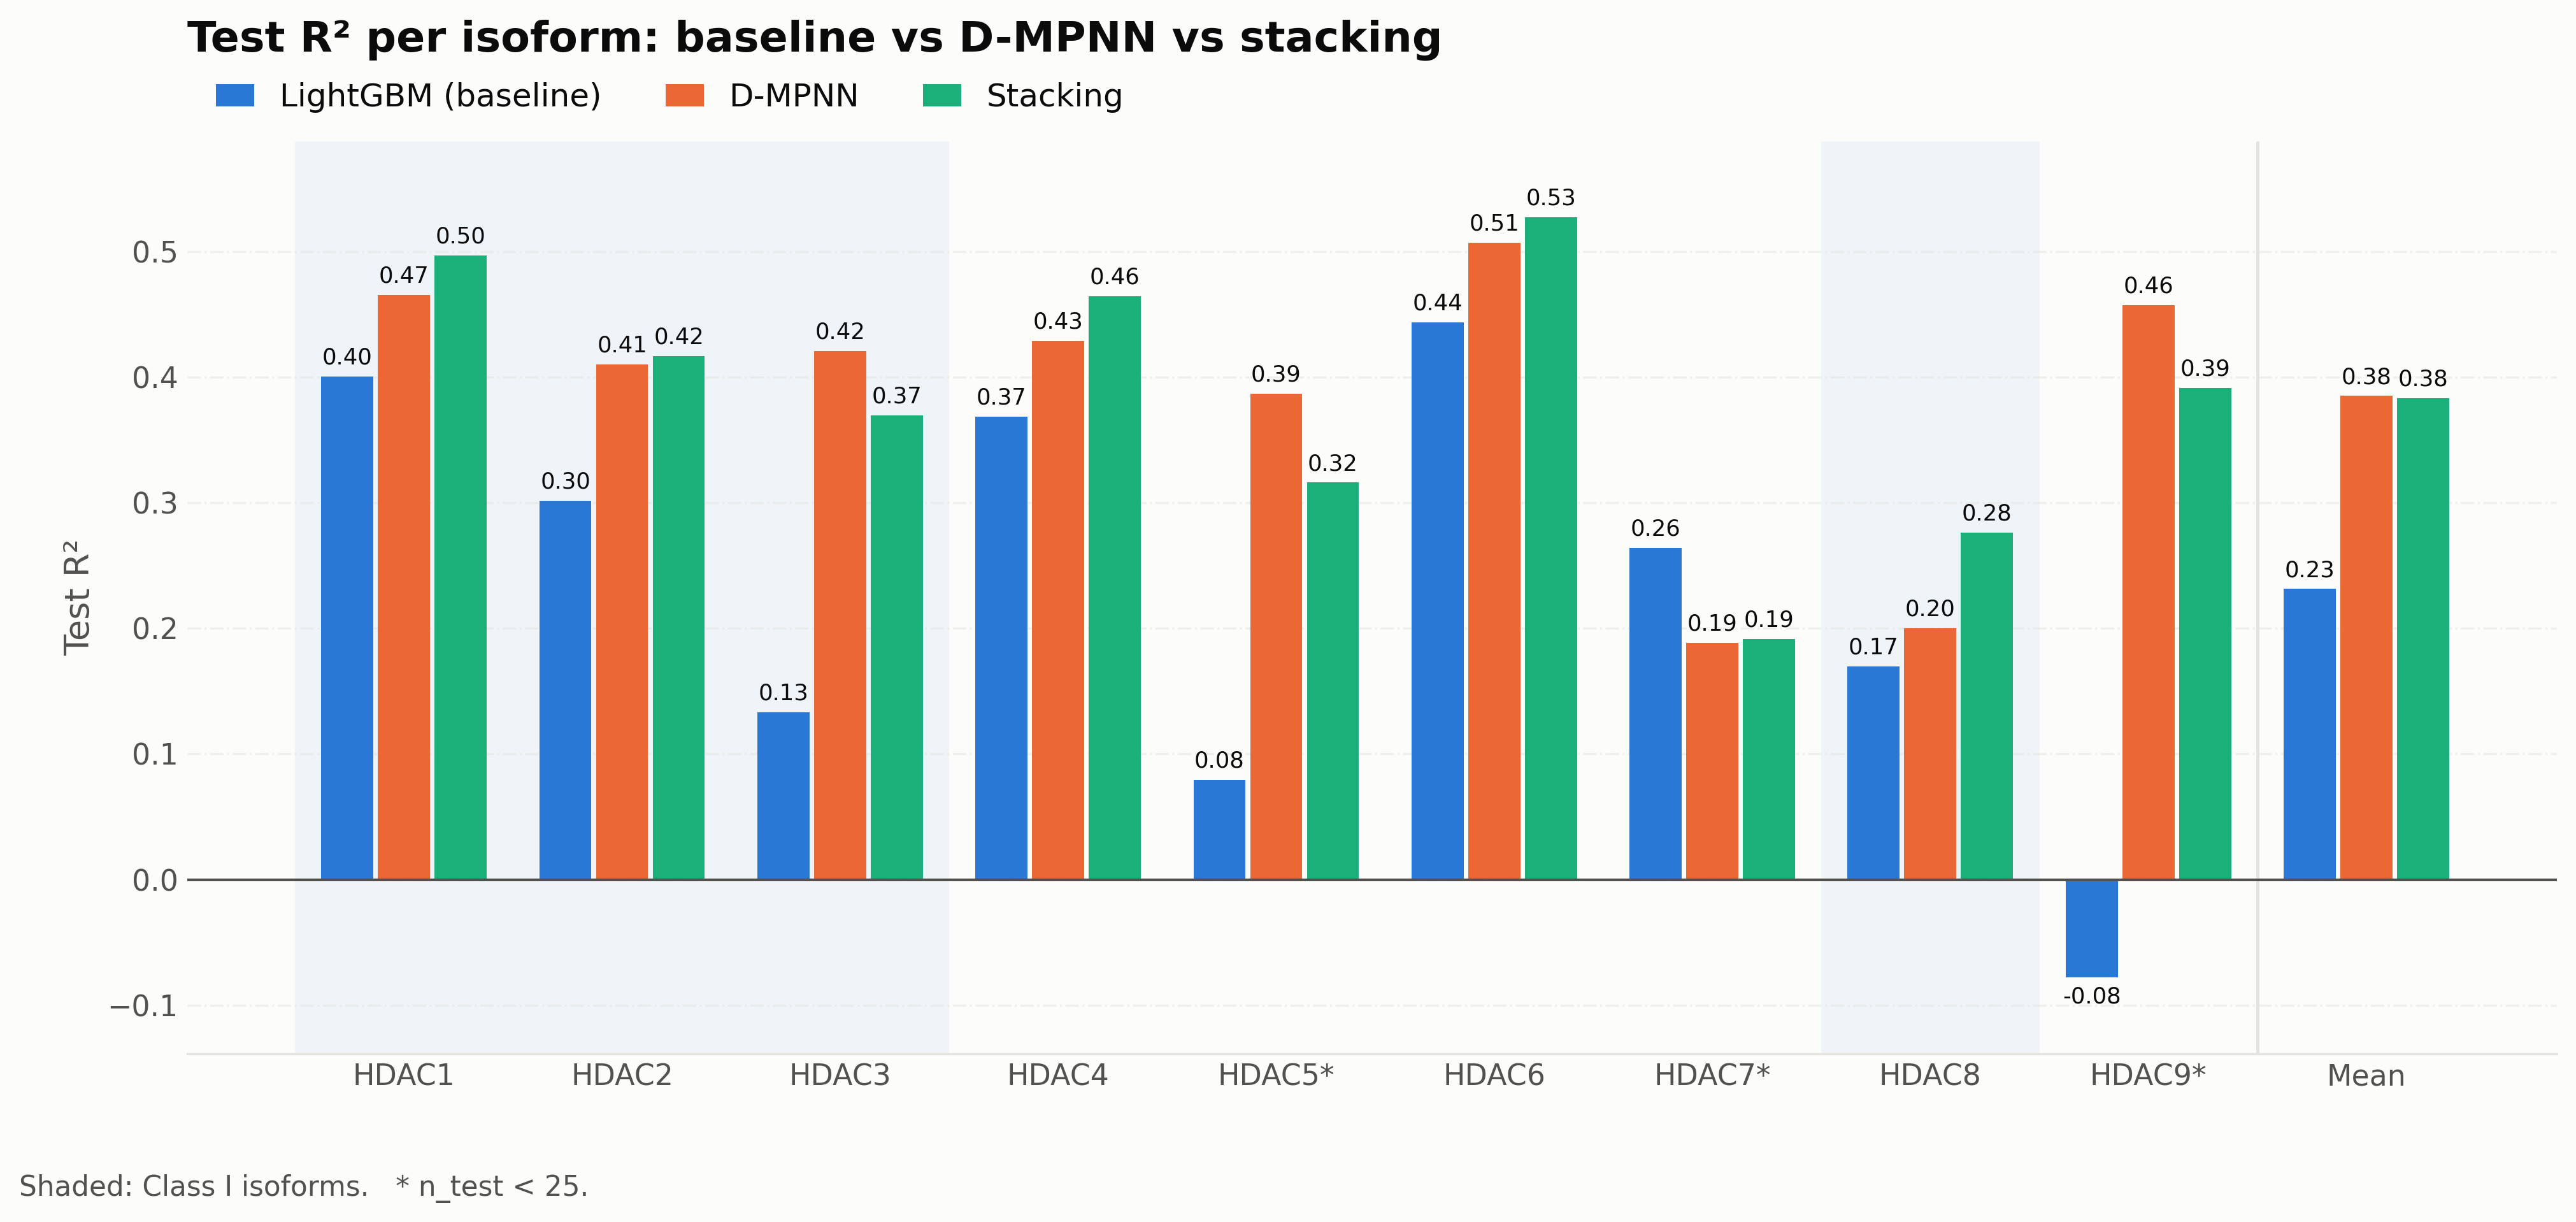

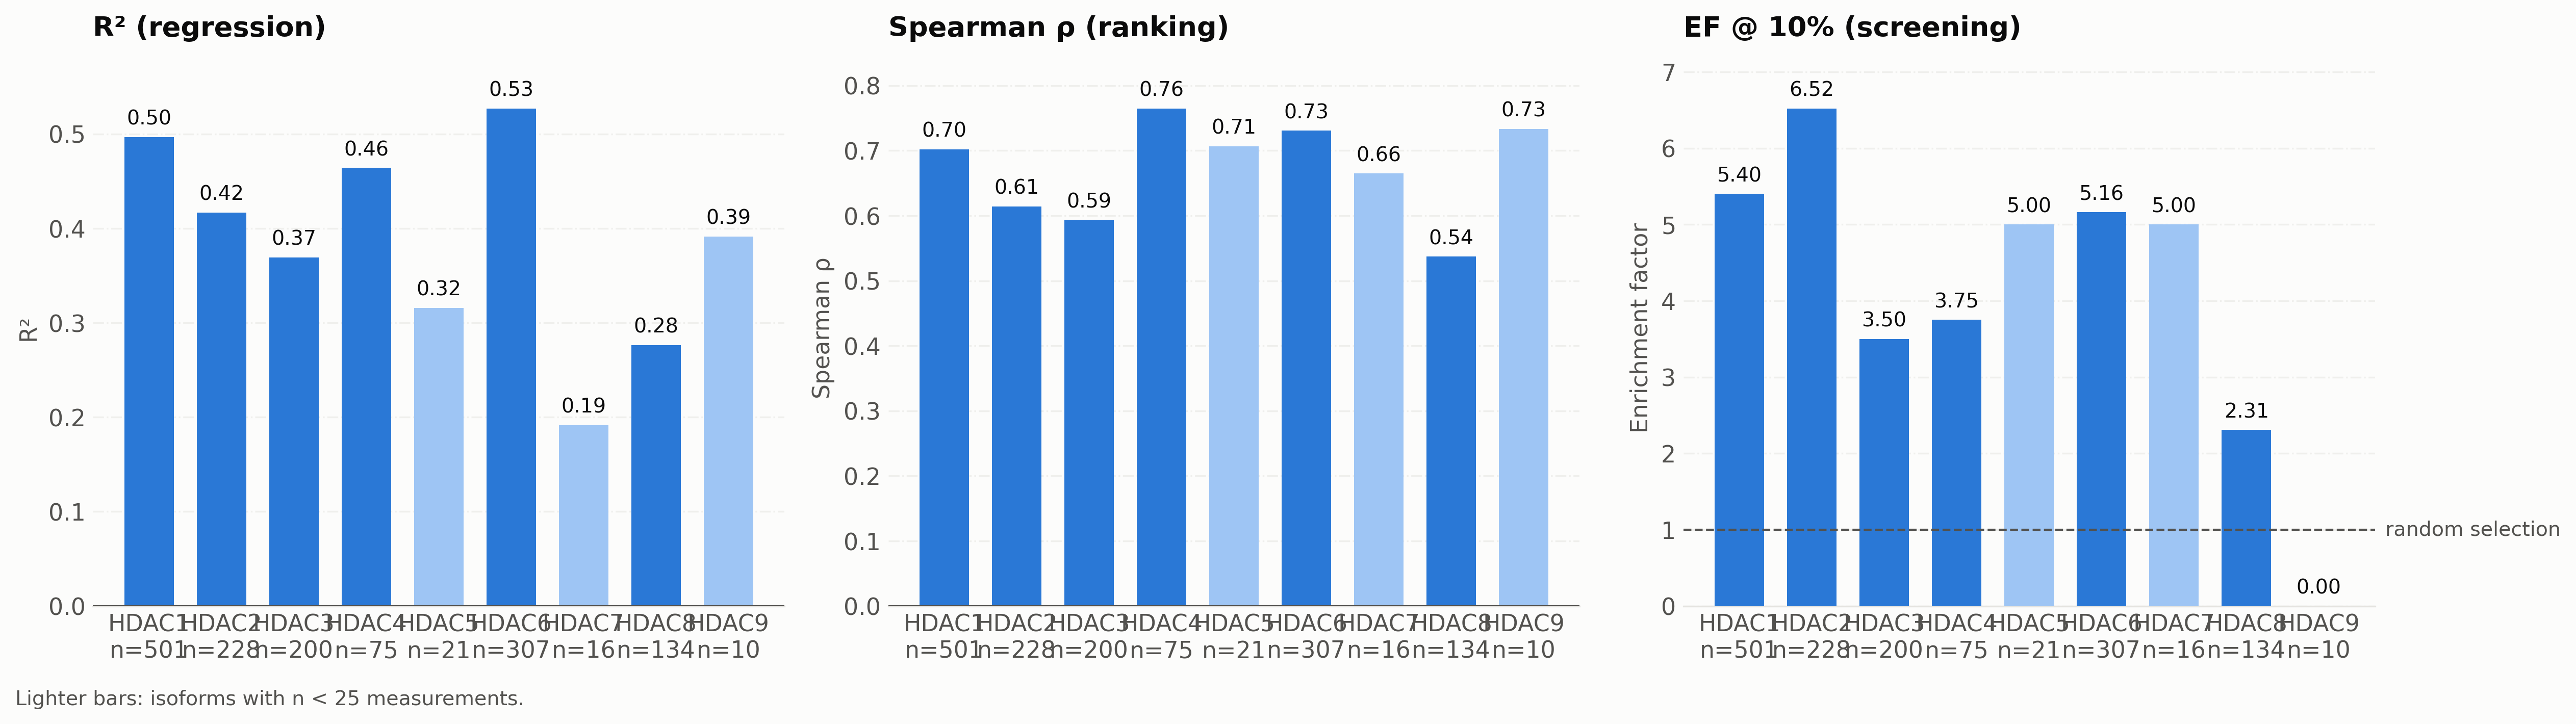

In [4]:
MODELS = ['LGBM', 'DMPNN', 'Stacking']

# Summary table written by main.ipynb, reindexed to isoform order
df = pd.read_csv(os.path.join(COMPARISON_OUT, 'per_isoform_consolidated.csv')).set_index('isoform').reindex(ISOFORMS).reset_index()
n_test = df['n_test'].values

# R2 per isoform (same function main.ipynb uses)
r2_comparison_plot(df, os.path.join(COMPARISON_OUT, 'r2_per_isoform_comparison.png'), underpowered_n=UNDERPOWERED_N)
display(Image(filename=os.path.join(COMPARISON_OUT, 'r2_per_isoform_comparison.png')))

# Stacking's R2 and ranking metrics: R2 vs Spearman vs EF@10%
r2_df_stacking = df[['isoform', 'R2_Stacking']].rename(columns={'R2_Stacking': 'r2'})
ranking_stacking = pd.read_csv(os.path.join(COMPARISON_OUT, 'ranking_stacking.csv'))
r2_vs_ranking_plot(r2_df_stacking, ranking_stacking, output_path=os.path.join(COMPARISON_OUT, 'r2_vs_ranking_stacking.png'))
display(Image(filename=os.path.join(COMPARISON_OUT, 'r2_vs_ranking_stacking.png')))

In [5]:
# D-MPNN validation-loss curves, one per fold, smoothed with an exponential moving
# average (EMA). Writes one all-folds plot and one per-fold plot per seed to outputs/loss/.

W = 5  # EMA window, in epochs
K = 3.0  # y-axis power-scale exponent (see set_power_yscale)
LOSS_DIR = os.path.join(DMPNN_OUT, 'loss_curves')
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']  # one colour per fold

# Seed/fold pairs found on disk
found = [re.search(r'seed(\d+)_cv_history_fold(\d+)\.csv$', f) for f in glob(os.path.join(DMPNN_OUT, 'seed*_cv_history_fold*.csv'))]
pairs = sorted((int(m.group(1)), int(m.group(2))) for m in found if m)
assert pairs, f'no {DMPNN_OUT}/seed*_cv_history_fold*.csv found: run main.ipynb first'
SEEDS, FOLDS = sorted({s for s, _ in pairs}), sorted({f for _, f in pairs})
print(f'found seeds {SEEDS}, folds {FOLDS}')
os.makedirs(LOSS_DIR, exist_ok=True)


# Power y-axis: compresses the 0-0.8 range and expands the high range where the curves sit.
def set_power_yscale(ax):
    ax.set_yscale('function', functions=(lambda y: np.power(np.clip(y, 0, None), K),
                                         lambda y: np.power(np.clip(y, 0, None), 1.0 / K)))
    ax.set_ylim(0.0, 1.15)
    ax.set_yticks([0.0, 0.4, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1])


# Loads one fold's history: epochs, raw validation MSE, and its EMA.
def load_fold(seed, fold):
    h = pd.read_csv(os.path.join(DMPNN_OUT, f'seed{seed}_cv_history_fold{fold}.csv'))
    val = h['val_mse'].values
    return h['epoch'].values, val, pd.Series(val).ewm(span=W, adjust=False).mean().values


# Draws one fold: faint raw curve plus a thicker EMA curve.
def plot_fold(ax, seed, fold, i, alpha_raw):
    ep, val, ema = load_fold(seed, fold)
    c = colors[i % len(colors)]
    ax.plot(ep, val, color=c, alpha=alpha_raw, linewidth=1.0)
    ax.plot(ep, ema, color=c, linewidth=2.4, label=f'fold {fold} (val_min={ema.min():.3f})')


# Finishes and saves a figure with a transparent background.
def save(fig, ax, path):
    ax.set_xlabel('epoch'); ax.set_ylabel('Validation MSE')
    set_power_yscale(ax); ax.grid(True, alpha=0.3); ax.legend(loc='upper right', framealpha=0.9)
    fig.tight_layout(); ax.patch.set_alpha(0.0); fig.savefig(path, dpi=150, transparent=True)
    plt.close(fig); print('saved', path)


for seed in SEEDS:
    fig, ax = plt.subplots(figsize=(13, 6.5))
    for i, fold in enumerate(FOLDS):
        plot_fold(ax, seed, fold, i, alpha_raw=0.22)
    ax.set_title(f'Validation loss D-MPNN — seed {seed}, EMA (w={W}) per fold')
    save(fig, ax, os.path.join(LOSS_DIR, f'seed{seed}_all_folds.png'))
    for i, fold in enumerate(FOLDS):
        fig, ax = plt.subplots(figsize=(13, 6.5))
        plot_fold(ax, seed, fold, i, alpha_raw=0.25)
        ax.set_title(f'Validation loss D-MPNN — seed {seed}, fold {fold}, EMA (w={W})')
        save(fig, ax, os.path.join(LOSS_DIR, f'seed{seed}_fold{fold}.png'))

found seeds [0, 1], folds [1, 2, 3, 4, 5]
saved outputs\dmpnn\loss_curves\seed0_all_folds.png
saved outputs\dmpnn\loss_curves\seed0_fold1.png
saved outputs\dmpnn\loss_curves\seed0_fold2.png
saved outputs\dmpnn\loss_curves\seed0_fold3.png
saved outputs\dmpnn\loss_curves\seed0_fold4.png
saved outputs\dmpnn\loss_curves\seed0_fold5.png
saved outputs\dmpnn\loss_curves\seed1_all_folds.png
saved outputs\dmpnn\loss_curves\seed1_fold1.png
saved outputs\dmpnn\loss_curves\seed1_fold2.png
saved outputs\dmpnn\loss_curves\seed1_fold3.png
saved outputs\dmpnn\loss_curves\seed1_fold4.png
saved outputs\dmpnn\loss_curves\seed1_fold5.png
